# Многорукие бандиты

Сравнение epsilon-greedy, Thompson Sampling и A/B-теста с равномерным трафиком по накопленному regret. В симуляции четыре варианта с конверсией 2%, 4%, 3.5% и 6%.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True})

In [2]:
true_rates = np.array([0.02, 0.04, 0.035, 0.06])
best_arm = int(np.argmax(true_rates))
best_rate = true_rates[best_arm]

def pull_arm(arm, rng):
    return int(rng.random() < true_rates[arm])

## 1. Cumulative regret

$$\operatorname{Regret}(T) = \sum_{t=1}^{T} \left(\mu^* - \mu_{A_t}\right)$$

`cumulative_regret` получает массив выбранных ручек `chosen_arms` и возвращает накопленные потери относительно лучшей ручки.

In [3]:
def cumulative_regret(chosen_arms):
    chosen_rates = true_rates[chosen_arms]
    instant_regret = best_rate - chosen_rates
    regret = np.cumsum(instant_regret)
    return regret

## 2. Epsilon-greedy

`select_epsilon_greedy_arm` с вероятностью `epsilon` выбирает случайную ручку, иначе — ручку с максимальной `estimated_rates`. `run_epsilon_greedy` сначала пробует каждую ручку по разу, дальше выбирает через `select_epsilon_greedy_arm`. В `counts` и `reward_sums` хранятся показы и награды каждой ручки.

In [4]:
def select_epsilon_greedy_arm(estimated_rates, epsilon, rng):
    if rng.random() < epsilon:
        return rng.integers(len(estimated_rates))
    return np.argmax(estimated_rates)


def run_epsilon_greedy(n_steps, epsilon, rng):
    n_arms = len(true_rates)
    counts = np.zeros(n_arms, dtype=int)
    reward_sums = np.zeros(n_arms, dtype=float)
    chosen_arms = []
    rewards = []
    for t in range(n_steps):
        if t < n_arms:
            arm = t
        else:
            estimated_rates = reward_sums / counts
            arm = select_epsilon_greedy_arm(estimated_rates, epsilon, rng)

        reward = pull_arm(arm, rng)
        counts[arm] += 1
        reward_sums[arm] += reward

        chosen_arms.append(arm)
        rewards.append(reward)

    return pd.DataFrame({
        't': np.arange(1, n_steps + 1),
        'arm': chosen_arms,
        'reward': rewards,
    })

## 3. Thompson Sampling

$$\theta_a \sim \operatorname{Beta}(\alpha_a, \beta_a), \qquad
\alpha_a \leftarrow \alpha_a + r, \quad \beta_a \leftarrow \beta_a + 1 - r$$

`alpha` и `beta` — параметры Beta-распределения каждой ручки. На каждом шаге выбирается ручка с максимальным сэмплом `sampled_rates`, после награды её параметры обновляются.

In [5]:
def run_thompson_sampling(n_steps, rng):
    n_arms = len(true_rates)
    alpha = np.ones(n_arms)
    beta = np.ones(n_arms)
    chosen_arms = []
    rewards = []

    for t in range(n_steps):
        sampled_rates = rng.beta(alpha, beta)
        arm = int(np.argmax(sampled_rates))

        reward = pull_arm(arm, rng)

        alpha[arm] += reward
        beta[arm] += 1 - reward

        chosen_arms.append(arm)
        rewards.append(reward)

    return pd.DataFrame({
        't': np.arange(1, n_steps + 1),
        'arm': chosen_arms,
        'reward': rewards,
    })

## 4. A/B-тест для сравнения

На каждом шаге выбирается случайная ручка с равной вероятностью.

In [6]:
def run_ab_test(n_steps, rng):
    arms = rng.integers(len(true_rates), size=n_steps)
    rewards = [pull_arm(arm, rng) for arm in arms]
    return pd.DataFrame({'t': np.arange(1, n_steps + 1), 'arm': arms, 'reward': rewards})

## 5. Один прогон на 5 000 шагов

`summary` — суммарная награда, итоговый regret и доля выборов лучшей ручки для каждой стратегии.

In [7]:
n_steps = 5000

hist_eps = run_epsilon_greedy(n_steps, epsilon=0.1, rng=np.random.default_rng(1))
hist_ts = run_thompson_sampling(n_steps, rng=np.random.default_rng(1))
hist_ab = run_ab_test(n_steps, rng=np.random.default_rng(1))
hists = [hist_eps, hist_ts, hist_ab]

summary = pd.DataFrame({
    'algorithm': ['epsilon_greedy', 'thompson_sampling', 'ab_test'],
    'total_reward': [h['reward'].sum() for h in hists],
    'final_regret': [cumulative_regret(h['arm'].to_numpy())[-1] for h in hists],
    'best_arm_share': [(h['arm'] == best_arm).mean() for h in hists],
})
summary

,algorithm,total_reward,final_regret,best_arm_share
0,epsilon_greedy,180,127.5200,0.0696
1,thompson_sampling,251,33.1350,0.7488
2,ab_test,187,105.4600,0.2568


В этом прогоне epsilon-greedy застрял на неоптимальной ручке: лучшей досталось 7% трафика.

## 6. 200 прогонов

Каждая стратегия запускается 200 раз с разными сидами. В таблице средний regret, его 10-й и 90-й перцентили и доля лучшей ручки. `stuck_share` — доля прогонов, в которых чаще всего выбиралась не лучшая ручка.

In [8]:
strategies = {
    'epsilon_greedy': lambda rng: run_epsilon_greedy(n_steps, epsilon=0.1, rng=rng),
    'thompson_sampling': lambda rng: run_thompson_sampling(n_steps, rng=rng),
    'ab_test': lambda rng: run_ab_test(n_steps, rng=rng),
}

regret_curves = {name: [] for name in strategies}
records = []
for seed in range(200):
    for name, run in strategies.items():
        arms = run(np.random.default_rng(seed))['arm'].to_numpy()
        regret_curves[name].append(cumulative_regret(arms))
        records.append({
            'algorithm': name,
            'final_regret': regret_curves[name][-1][-1],
            'best_arm_share': (arms == best_arm).mean(),
            'stuck': np.bincount(arms, minlength=len(true_rates)).argmax() != best_arm,
        })

runs = pd.DataFrame(records)
runs_summary = runs.groupby('algorithm', sort=False).agg(
    mean_regret=('final_regret', 'mean'),
    regret_p10=('final_regret', lambda s: s.quantile(0.1)),
    regret_p90=('final_regret', lambda s: s.quantile(0.9)),
    best_arm_share=('best_arm_share', 'mean'),
    stuck_share=('stuck', 'mean'),
)
runs_summary.loc['ab_test', 'stuck_share'] = np.nan
runs_summary

,mean_regret,regret_p10,regret_p90,best_arm_share,stuck_share
algorithm,,,,,
epsilon_greedy,42.5434,13.6680,103.5315,0.6796,0.1750
thompson_sampling,30.8188,15.7790,48.4045,0.7515,0.0400
ab_test,106.1790,104.9465,107.5655,0.2505,NaN


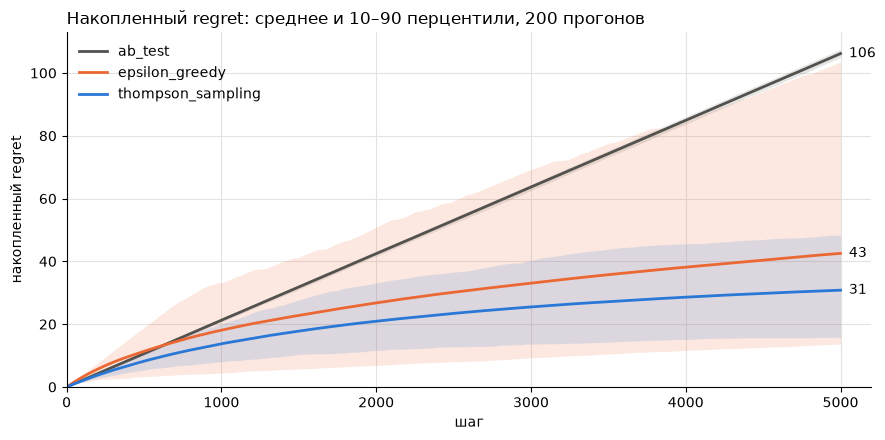

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
steps = np.arange(1, n_steps + 1)
for name, color in [('ab_test', '#52514e'), ('epsilon_greedy', '#eb6834'), ('thompson_sampling', '#2a78d6')]:
    curves = np.array(regret_curves[name])
    mean = curves.mean(axis=0)
    p10, p90 = np.percentile(curves, [10, 90], axis=0)
    ax.fill_between(steps, p10, p90, color=color, alpha=0.15, lw=0)
    ax.plot(steps, mean, color=color, lw=2, label=name)
    ax.annotate(f'{mean[-1]:.0f}', (steps[-1], mean[-1]), xytext=(6, 0),
                textcoords='offset points', va='center', fontsize=10)
ax.set_xlim(0, n_steps * 1.04)
ax.set_ylim(0, None)
ax.set_xlabel('шаг')
ax.set_ylabel('накопленный regret')
ax.set_title('Накопленный regret: среднее и 10–90 перцентили, 200 прогонов', loc='left')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig('../images/bandits_regret.png', dpi=150, bbox_inches='tight')
plt.show()

## Что сделано

- Реализованы cumulative regret, epsilon-greedy (ε = 0.1) и Thompson Sampling, для сравнения — A/B-тест с равномерным трафиком.
- По 200 прогонам на 5 000 шагов средний regret составил 31 у Thompson Sampling, 43 у epsilon-greedy и 106 у A/B-теста. Лучшая ручка получает 75%, 68% и 25% трафика.
- Epsilon-greedy застревает на неоптимальной ручке в 17.5% прогонов, в том числе в прогоне с сидом 1.
- Бандит теряет меньше конверсий, а A/B-тест равномерно собирает данные по всем вариантам и даёт честную оценку эффекта каждого.